# Fine-tuning BART for Task-Oriented Dialogue Generation

## Project Goal

The goal of this project is to build a response-generation system for dialogues based on the pretrained `facebook/bart-base` model. The system is trained on a set of dialogues about finding service providers and booking appointments.

The project covers building training examples with the context of previous turns, fine-tuning the model, evaluating generation quality on held-out data, and analyzing errors.

To keep the experiment reproducible, it uses fixed random seeds, separate training, validation and test sets, and saves the trained weights and tokenizer.

## Technologies

- Python and PyTorch;
- Hugging Face Transformers;
- the `facebook/bart-base` model;
- the Evaluate and SacreBLEU libraries for generation evaluation;
- BLEU and ROUGE-L metrics.

## Methodology

The data is split into training, validation and test sets in an approximate 80:10:10 ratio. The training set is used to optimize model parameters, the validation set to monitor training and select the best checkpoint, and the test set for the final evaluation.

The notebook also examines how the input length limit affects the data and analyzes cases where the model generates irrelevant or factually unsupported responses.

## 1. Environment Setup

This step imports the libraries for data processing, model training and metric computation. Random seeds are fixed for Python, NumPy and PyTorch to reduce the influence of randomness on the results.

If a compatible GPU is available, training runs on it. Otherwise the CPU is used, but training time may increase significantly.

In [4]:
import sys
import json
import random
import numpy as np
import pandas as pd
import torch
from pathlib import Path
from sklearn.model_selection import train_test_split
from torch.utils.data import Dataset, DataLoader
from transformers import (
    BartForConditionalGeneration,
    BartTokenizer,
    get_linear_schedule_with_warmup,
)

SEED = 42


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    if hasattr(torch.backends, "cudnn"):
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False


set_seed()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Device:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu128
Device: cuda
GPU: Tesla T4


## 2. Data Loading and Preprocessing

The input dataset contains dialogues represented as sequences of turns from different speakers. The JSON file is opened with UTF-8 encoding to ensure the text is read correctly.

A training example is created for every system turn: the preceding turns form the input context, and the current system turn is the target response. This teaches the model to generate responses that take the course of the conversation into account, not just the latest user message.

> **Note:** if you run the notebook outside Kaggle, change `DATA_PATH` to the path of your own JSON file.

In [5]:
DATA_PATH = Path(
    "/kaggle/input/datasets/bodyastar/services/services.json"
)


def read_json_file(filename):
    with open(filename, encoding="utf-8") as file:
        return json.load(file)


json_data = read_json_file(DATA_PATH)

print("Number of dialogues:", len(json_data))
print("Data type:", type(json_data).__name__)

Number of dialogues: 125
Data type: list


### 2.1. Building Examples with a Context Window

The experiment uses a context of up to three preceding turns. If fewer turns are available, all of them are used. Only examples whose target turn belongs to the system are included.

Each dataset item has two fields: `input` (the dialogue context) and `output` (the system response). The ID of the source dialogue is stored as well, so that turns from the same dialogue can later be kept in a single split.

In [6]:
CONTEXT_WINDOW = 3


def build_bart_dataset(jsondata, context_window=CONTEXT_WINDOW):
    results = []

    for dialogue_id, dialogue in enumerate(jsondata):
        turns = dialogue.get("turns", [])

        for i, target_turn in enumerate(turns):
            if target_turn.get("speaker") != "SYSTEM":
                continue
            if i == 0:
                continue

            context_turns = turns[max(0, i - context_window):i]

            context = "\n".join(
                f"{turn['speaker']}: {turn['utterance']}"
                for turn in context_turns
            )
            response = target_turn.get("utterance", "").strip()

            if not context.strip() or not response:
                continue

            results.append({
                "dialogue_id": dialogue_id,
                "input": context,
                "output": response,
            })

    return results


bart_data = build_bart_dataset(json_data)
print("Number of examples:", len(bart_data))
print("\nExample:")
print("INPUT:\n" + bart_data[0]["input"])
print("OUTPUT:\n" + bart_data[0]["output"])

Number of examples: 1123

Example:
INPUT:
USER: Please find me a dentist in Cupertino.
OUTPUT:
Okay, I found 4 dentists in the area. Would you like Cabanas Carol L it is located in Cupertino.


## 3. Data Analysis and Splitting

Before training, the dataset structure is checked for missing values and duplicates. Special attention is paid to the split: all examples from one source dialogue go into a single subset only.

This prevents data leakage, where similar turns from the same dialogue would be used for both training and testing. The data is split into train, validation and test sets in an approximate 80:10:10 ratio.

> **Note:** the 80:10:10 ratio is approximate, because the split is done by whole dialogues rather than individual turns.

In [7]:
df = pd.DataFrame(bart_data)

print("Dataset shape:", df.shape)
print("\nMissing values:")
print(df[["input", "output"]].isna().sum())
print("\nEmpty inputs:", (df["input"].str.strip() == "").sum())
print("Empty responses:", (df["output"].str.strip() == "").sum())
print("Duplicate input/output pairs:",
      df.duplicated(subset=["input", "output"]).sum())
print("Unique dialogues:", df["dialogue_id"].nunique())

# Split by dialogue ID to avoid dialogue-level leakage
dialogue_ids = df["dialogue_id"].unique()

train_ids, temp_ids = train_test_split(
    dialogue_ids,
    test_size=0.20,
    random_state=SEED,
)
val_ids, test_ids = train_test_split(
    temp_ids,
    test_size=0.50,
    random_state=SEED,
)

train_df = df[df["dialogue_id"].isin(train_ids)].reset_index(drop=True)
val_df = df[df["dialogue_id"].isin(val_ids)].reset_index(drop=True)
test_df = df[df["dialogue_id"].isin(test_ids)].reset_index(drop=True)

print("\nSplit sizes:")
print(f"Train:      {len(train_df)} ({len(train_df) / len(df):.1%})")
print(f"Validation: {len(val_df)} ({len(val_df) / len(df):.1%})")
print(f"Test:       {len(test_df)} ({len(test_df) / len(df):.1%})")

Dataset shape: (1123, 3)

Missing values:
input     0
output    0
dtype: int64

Empty inputs: 0
Empty responses: 0
Duplicate input/output pairs: 1
Unique dialogues: 125

Split sizes:
Train:      908 (80.9%)
Validation: 102 (9.1%)
Test:       113 (10.1%)


## 4. Tokenization and Sequence Length Analysis

The tokenizer of `facebook/bart-base` is used to convert text into numerical sequences.

In the initial experiment the maximum input length was 64 tokens. Such a limit can cut off part of the context, so before training we measure how many examples exceed it.

For this experiment the input limit is set to 128 tokens and the target limit to 64 tokens. This preserves more context without excessively increasing the computational cost.

In [8]:
MODEL_NAME = "facebook/bart-base"
MAX_INPUT_LEN = 128
MAX_TARGET_LEN = 64

tokenizer = BartTokenizer.from_pretrained(MODEL_NAME)


def get_token_length(text):
    return len(
        tokenizer(
            text,
            truncation=False,
            add_special_tokens=True,
        )["input_ids"]
    )


df["input_tokens"] = df["input"].apply(get_token_length)
df["output_tokens"] = df["output"].apply(get_token_length)

for column, limit in [
    ("input_tokens", 64),
    ("input_tokens", MAX_INPUT_LEN),
    ("output_tokens", MAX_TARGET_LEN),
]:
    count = int((df[column] > limit).sum())
    percentage = count / len(df) * 100
    print(
        f"{column}: more than {limit} tokens - "
        f"{count} examples ({percentage:.2f}%)"
    )

print("\nLength statistics:")
print(df[["input_tokens", "output_tokens"]].describe().round(2))

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

input_tokens: more than 64 tokens - 90 examples (8.01%)
input_tokens: more than 128 tokens - 0 examples (0.00%)
output_tokens: more than 64 tokens - 0 examples (0.00%)

Length statistics:
       input_tokens  output_tokens
count       1123.00        1123.00
mean          42.93          16.04
std           16.60           7.58
min            9.00           4.00
25%           33.00          10.00
50%           43.00          14.00
75%           53.00          21.00
max          116.00          53.00


Comparing the share of inputs above 64 tokens with the share above 128 tokens provides a data-driven justification for the chosen `MAX_INPUT_LEN`.

## 5. Model and Dataset Preparation

The base model is `facebook/bart-base`, a pretrained encoder-decoder transformer designed for text generation and transformation.

In this experiment the encoder parameters are frozen and training focuses on the decoder. This reduces the number of parameters being updated, but also limits how far the encoder can adapt to the specifics of the dialogues.

The `DialogDataset` class tokenizes inputs and responses. Padding positions in the target sequences are replaced with `-100` so that they are ignored when computing the loss.

In [9]:
class DialogDataset(Dataset):
    def __init__(self, dataframe):
        self.inputs = dataframe["input"].tolist()
        self.outputs = dataframe["output"].tolist()

    def __len__(self):
        return len(self.inputs)

    def __getitem__(self, idx):
        input_enc = tokenizer(
            self.inputs[idx],
            max_length=MAX_INPUT_LEN,
            padding="max_length",
            truncation=True,
            return_tensors="pt",
        )
        target_enc = tokenizer(
            self.outputs[idx],
            max_length=MAX_TARGET_LEN,
            padding="max_length",
            truncation=True,
            return_tensors="pt",
        )

        labels = target_enc["input_ids"].squeeze(0)
        labels[labels == tokenizer.pad_token_id] = -100

        return {
            "input_ids": input_enc["input_ids"].squeeze(0),
            "attention_mask": input_enc["attention_mask"].squeeze(0),
            "labels": labels,
        }


BATCH_SIZE = 8

train_dataset = DialogDataset(train_df)
val_dataset = DialogDataset(val_df)
test_dataset = DialogDataset(test_df)

loader_generator = torch.Generator()
loader_generator.manual_seed(SEED)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=loader_generator,
)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

print("Batches per epoch (train):", len(train_loader))
print("Batches (validation):", len(val_loader))
print("Batches (test):", len(test_loader))

Batches per epoch (train): 114
Batches (validation): 13
Batches (test): 15


## 6. Fine-tuning BART

Training runs for at most 10 epochs using the AdamW optimizer and a learning rate scheduler with warmup. After each epoch, the average loss is computed on the training and validation sets.

The training loss shows how well the model reproduces the responses it is optimized on. The validation loss helps assess how well the model generalizes to dialogues not used for training.

The checkpoint with the lowest validation loss is saved. If the validation loss does not improve for three consecutive epochs, training stops early (early stopping).

> **Notes**
> - Freezing the encoder is one experimental option, not a guaranteed optimal approach. Its effect has to be verified with the metrics.
> - BART shares one token embedding matrix between the encoder, the decoder and the output layer, so freezing the encoder parameters also freezes these shared embeddings. The printed parameter counts below show how many parameters are actually trained.
> - Outside Kaggle, replace `/kaggle/working/bart_best` with a suitable directory.

In [ ]:
CHECKPOINT_DIR = Path("/kaggle/working/bart_best")
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

model = BartForConditionalGeneration.from_pretrained(MODEL_NAME)
model = model.to(device)

# Freeze encoder parameters
for param in model.get_encoder().parameters():
    param.requires_grad = False

trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
total_params = sum(p.numel() for p in model.parameters())
print(f"Trainable parameters: {trainable_params:,} / {total_params:,} "
      f"({trainable_params / total_params:.1%})")

LEARNING_RATE = 3e-5
EPOCHS = 10
PATIENCE = 3

optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=LEARNING_RATE,
)

total_steps = len(train_loader) * EPOCHS
scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=int(0.1 * total_steps),
    num_training_steps=total_steps,
)


def evaluate_loss(model, loader):
    model.eval()
    total_loss = 0.0
    total_examples = 0

    with torch.no_grad():
        for batch in loader:
            batch = {
                key: value.to(device)
                for key, value in batch.items()
            }
            outputs = model(**batch)
            batch_size = batch["input_ids"].size(0)
            total_loss += outputs.loss.item() * batch_size
            total_examples += batch_size

    return total_loss / total_examples


history = []
best_val_loss = float("inf")
epochs_without_improvement = 0

for epoch in range(1, EPOCHS + 1):
    model.train()
    running_loss = 0.0
    seen_examples = 0

    for batch in train_loader:
        batch = {
            key: value.to(device)
            for key, value in batch.items()
        }

        optimizer.zero_grad()
        outputs = model(**batch)
        loss = outputs.loss
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        scheduler.step()

        batch_size = batch["input_ids"].size(0)
        running_loss += loss.item() * batch_size
        seen_examples += batch_size

    # Training loss is averaged over the epoch (dropout is active)
    train_loss = running_loss / seen_examples
    val_loss = evaluate_loss(model, val_loader)

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss,
    })

    print(f"Epoch {epoch:02d}/{EPOCHS} | "
          f"train loss: {train_loss:.4f} | val loss: {val_loss:.4f}")

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        epochs_without_improvement = 0
        model.save_pretrained(CHECKPOINT_DIR)
        tokenizer.save_pretrained(CHECKPOINT_DIR)
        print("  -> new best checkpoint saved")
    else:
        epochs_without_improvement += 1
        if epochs_without_improvement >= PATIENCE:
            print(f"Early stopping: no improvement for {PATIENCE} epochs.")
            break

history_df = pd.DataFrame(history)
history_df.round(4)

## 7. Loss Dynamics Analysis

A plot of the training and validation losses is used to assess how training progressed. Comparing the two curves helps reveal possible signs of overfitting.

If the training loss keeps decreasing while the validation loss increases, this may indicate worse generalization. Final conclusions should also take into account the generation metrics and example responses.

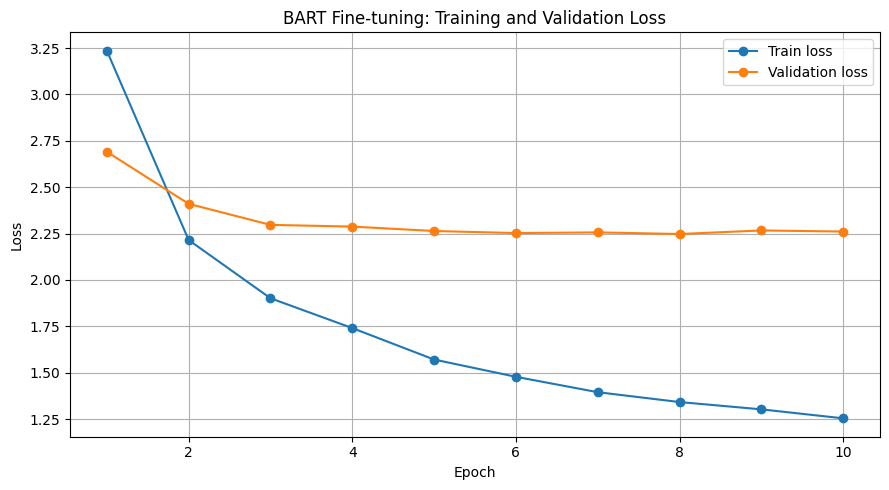

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))
plt.plot(
    history_df["epoch"],
    history_df["train_loss"],
    marker="o",
    label="Train loss",
)
plt.plot(
    history_df["epoch"],
    history_df["val_loss"],
    marker="o",
    label="Validation loss",
)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("BART Fine-tuning: Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## 8. Evaluating Generation Quality

The loss value alone is not enough to assess a dialogue system. After training, the model is therefore evaluated on the test set, which was not used to optimize parameters or to select the checkpoint.

Two metrics are used:

- **BLEU** measures n-gram overlap between generated and reference responses.
- **ROUGE-L** measures similarity based on the longest common subsequence.

Both metrics allow a quantitative comparison of generated text against references. However, they do not guarantee factual correctness: a response can be lexically close to the reference yet contain a wrong business name or appointment time.

First, install the required libraries (in Kaggle this can be done in a separate cell).

In [12]:
%pip install -q evaluate sacrebleu rouge_score

Note: you may need to restart the kernel to use updated packages.


### 8.1. Loading the Best Checkpoint

The test evaluation uses the saved checkpoint with the lowest validation loss. This keeps model selection and the final evaluation consistent.

In [ ]:
import evaluate

model = BartForConditionalGeneration.from_pretrained(
    CHECKPOINT_DIR
).to(device)
tokenizer = BartTokenizer.from_pretrained(CHECKPOINT_DIR)

bleu_metric = evaluate.load("sacrebleu")
rouge_metric = evaluate.load("rouge")

print("Best validation loss:", round(best_val_loss, 4))
print("Model for evaluation loaded.")

### 8.2. Generating Responses and Computing Metrics

The model receives the dialogue context and generates a response using beam search. The parameter `num_beams=4` lets the model consider several candidate sequences, and `no_repeat_ngram_size=3` prevents repeated trigrams. The same decoding parameters are used for all test generation.

Responses are generated for the whole test set, after which BLEU and ROUGE-L are computed. BLEU is computed at the corpus level (SacreBLEU), while ROUGE-L is an average of per-example scores (Evaluate).

In [14]:
GEN_KWARGS = {
    "max_new_tokens": MAX_TARGET_LEN,
    "num_beams": 4,
    "early_stopping": True,
    "no_repeat_ngram_size": 3,
}


def generate_response(input_text):
    model.eval()
    encoded = tokenizer(
        input_text,
        max_length=MAX_INPUT_LEN,
        truncation=True,
        return_tensors="pt",
    ).to(device)

    with torch.no_grad():
        generated = model.generate(**encoded, **GEN_KWARGS)

    return tokenizer.decode(generated[0], skip_special_tokens=True)


test_predictions = []
test_references = test_df["output"].tolist()

model.eval()
for start in range(0, len(test_df), BATCH_SIZE):
    batch_df = test_df.iloc[start:start + BATCH_SIZE]

    encoded = tokenizer(
        batch_df["input"].tolist(),
        max_length=MAX_INPUT_LEN,
        truncation=True,
        padding=True,
        return_tensors="pt",
    ).to(device)

    with torch.no_grad():
        generated = model.generate(**encoded, **GEN_KWARGS)

    test_predictions.extend(
        tokenizer.batch_decode(generated, skip_special_tokens=True)
    )

bleu_result = bleu_metric.compute(
    predictions=test_predictions,
    references=[[ref] for ref in test_references],
)
rouge_result = rouge_metric.compute(
    predictions=test_predictions,
    references=test_references,
)
test_loss = evaluate_loss(model, test_loader)

metrics = {
    "bleu": round(bleu_result["score"], 2),
    "rougeL": round(rouge_result["rougeL"], 4),
    "test_loss": round(test_loss, 4),
    "best_val_loss": round(best_val_loss, 4),
}

print(json.dumps(metrics, indent=2))

{
  "bleu": 12.83,
  "rougeL": 0.319,
  "test_loss": 1.9633,
  "best_val_loss": 2.2478
}


`evaluate_loss` computes the test loss using the reference responses (teacher forcing), so the test set is used only for the final report and never for tuning hyperparameters.

### How to Interpret the Results

- BLEU is reported on a 0 to 100 scale in the SacreBLEU implementation.
- ROUGE-L in the Evaluate library is typically returned in the range 0 to 1.
- A lower loss does not necessarily mean higher BLEU and ROUGE-L.
- Metric values should only be compared under identical evaluation conditions.

## 9. Qualitative Analysis of Generated Responses

Automatic metrics do not capture all the problems of a dialogue system. We therefore also inspect concrete "context - reference response - generated response" triples.

Particular attention is paid to factual errors, wrong business names, a mismatch in the type of service, incorrect interpretation of user confirmation, and loss of information from earlier turns.

This analysis helps determine whether an error stems from insufficient context, a limited set of training examples, or the tendency of generative models to produce plausible but unsupported text.

In [15]:
error_analysis = test_df[["input", "output"]].copy()
error_analysis["prediction"] = test_predictions

error_analysis["reference_length"] = (
    error_analysis["output"].str.split().str.len()
)
error_analysis["prediction_length"] = (
    error_analysis["prediction"].str.split().str.len()
)
error_analysis["exact_match"] = (
    error_analysis["output"].str.strip().str.lower()
    == error_analysis["prediction"].str.strip().str.lower()
)

print("Exact match with the reference:")
print(f"{error_analysis['exact_match'].mean():.2%}")

print("\nExample responses:")
display(
    error_analysis[
        ["input", "output", "prediction", "exact_match"]
    ].head(15)
)

Exact match with the reference:
1.77%

Example responses:


,input,output,prediction,exact_match
0,USER: Please find me a dentist in Cupertino.,"Okay, I found 4 dentists in the area. Would yo...",I found 10 dentists in Cupertino. How about A ...,False
1,USER: Please find me a dentist in Cupertino.\n...,what day would you like the appointment?,I found 4 dentists in Cupertino. Would you lik...,False
2,USER: Yes that sounds good I have to make an a...,Okay please confirm; appointment scheduled for...,Please confirm the following details: the name...,False
3,USER: The 12th of March would be perfect.\nSYS...,"Okay, your dentist appointment has been schedu...",Please confirm the following details: appointm...,False
4,"USER: Yes, that is correct.\nSYSTEM: Okay, you...","You're welcome, have a nice day.",Have a great day.,False
5,USER: Find me a dentist.,What city?,Which city should I search in?,False
6,USER: Find me a dentist.\nSYSTEM: What city?\n...,A J Dental lab is located in San Jose.,I found 10 dentists in San Jose. How about App...,False
7,USER: San Jose.\nSYSTEM: A J Dental lab is loc...,No they don't offer cosmetic services and thei...,Their number is 408-286-4371.,False
8,USER: Do they offer cosmetic services and what...,Confirm you want to book an appointment at A J...,Please confirm the following details: the name...,False
9,USER: Book me an appointment for the 2nd of th...,Confirm the appointment will be next Friday at...,Confirm you want to book an appointment at A J...,False


Exact match is a supporting metric, not a full quality criterion. The model may answer correctly using different wording, so the absence of an exact match does not always mean an error.

### 9.1. Identifying Potentially Problematic Responses

For manual analysis we select responses with a large length difference between the reference and the prediction, as well as examples without an exact match. This is not automatic proof of an error, only a way to find cases that deserve inspection.

Business names, addresses, phone numbers and appointment times should be checked separately, since even a grammatically correct response may contain wrong facts.

In [16]:
error_analysis["length_difference"] = abs(
    error_analysis["reference_length"]
    - error_analysis["prediction_length"]
)

candidates = error_analysis[
    ~error_analysis["exact_match"]
].sort_values("length_difference", ascending=False)

display(
    candidates[
        ["input", "output", "prediction", "length_difference"]
    ].head(10)
)

,input,output,prediction,length_difference
61,USER: I would love to go with this one.I must ...,What is the best time for you?,Please confirm the following details: The name...,24
34,USER: I would like to book an appointment with...,What date would you like your appointment for?,Please confirm the following details: the name...,20
66,USER: Please find me a unisex hair salon in SFO,There are 10 salons I think you'd like. 1512 B...,What city should I search in?,13
28,"USER: Yes, I need to make the booking still, i...","Great, I booked that appointment",Please confirm the following details: you want...,12
97,USER: I would like to have it set up for 3rd o...,I have confirmed the appointment and everythin...,I have confirmed your appointment. The name of...,11
8,USER: Do they offer cosmetic services and what...,Confirm you want to book an appointment at A J...,Please confirm the following details: the name...,11
24,USER: I need one in San Carlos\nSYSTEM: How ab...,"Just to confirm, I am booking an appointment w...",What time would you like your appointment?,10
83,USER: Where is it? Do you have the phone and a...,I know 10 salons around Palo Alto. How about 1...,The salon's phone number is 650-344-3010.,10
43,USER: monday next week at 13:00\nSYSTEM: pleas...,appointment booking successful,please confirm book appointment at 1 pm next m...,10
3,USER: The 12th of March would be perfect.\nSYS...,"Okay, your dentist appointment has been schedu...",Please confirm the following details: appointm...,10


### 9.2. Manual labeling of selected examples

Five examples were labeled by hand: one from the whole test set and four from the ten cases with the largest length difference. The labels illustrate typical behavior; the statistics below the table are computed on all 113 test predictions.

| Test idx | Last user turn | Reference | Prediction | Label | Reason |
|---|---|---|---|---|---|
| 25 | "No, I need it for the 5th" (the system had asked to confirm a booking with Cofield Marianne for March 14th) | Just to confirm, you need an appointment for 4:30 pm next Tuesday? | Just to confirm, you want an appointment with Cofield Marianne at 4:30 pm on March 5th? | **Correct** | Right dialogue act (confirm the corrected date). The provider, time and date are all supported by the context; only the wording differs from the reference. |
| 97 | "Yes, that is exactly right." (confirming Stags Barbershop, 3 March, 4 pm) | I have confirmed the appointment and everything is a go. | I have confirmed your appointment. The name of the salon is Stags Barbershop, and the appointment is at 4 pm tomorrow. | **Partially correct** | Right dialogue act, correct provider and time, but the relative date is wrong: the context says "the day after tomorrow", the prediction says "tomorrow". |
| 61 | "Make it on the 12th." (date given, time still missing) | What is the best time for you? | Please confirm the following details: The name of the hair stylist is Great Clips, the appointment is on March 12th at 12:30 pm, and the appointment will be on that date. | **Incorrect** | Premature confirmation while a required slot (time) is missing. The provider ("Great Clips", a hair stylist in a dentist dialogue) and the time (12:30 pm) are invented and not supported by the context. |
| 43 | "yes" (confirming a booking at 1 pm next Monday) | appointment booking successful | please confirm book appointment at 1 pm next monday with pineda lady fangirl | **Incorrect** | The user has already confirmed, but the model repeats the previous system turn instead of reporting success. It also completes the truncated provider name "pineda lady f" into "pineda lady fangirl". |
| 83 | "I'm looking for a salon in Palo Alto? Do you know some salon around there?" (the previous turn gave a phone number) | I know 10 salons around Palo Alto. How about 18/8 Fine Men's Salons - Palo Alto? | The salon's phone number is 650-344-3010. | **Incorrect** | Ignores the latest request and repeats an earlier answer. The number is copied from the context, so it is not a hallucination, but the response is unresponsive. The reference names a provider from search results that the input does not contain. |

**Statistics over all 113 test predictions**

- **Confirmation template:** "Please confirm the following details..." starts 18 predictions (15.9%), against 2.0% of the training outputs (18 of 908). In 10 of the 18 the reference is not a confirmation request: a slot is still missing (e.g. idx 34, 61) or the user has already confirmed (e.g. idx 28, 3).
- **Unsupported provider names:** 30 predictions (26.5%) name one of four frequent providers (Great Clips, A J Dental Lab, 1512 Barber Shop, Apple Dental Practice) that does not appear in the input. "Great Clips" alone appears 15 times, 7 of them in dentist dialogues.
- **Phone numbers and addresses:** 11 predictions contain a phone number. Three are copied from the context; the other 8 are not in the input, and all 8 end in "286-4371" with different area codes. Only one of the 8 matches the reference (idx 67). The address "1532 20th Street" appears 4 times and is never supported by the input.
- **Ignored information:** in 3 of the 8 cases where the model asks which city to search in, the user had already named the city (idx 38, 66, 99).
- **Premature closing:** 21 predictions are a closing phrase ("Have a great day"), but in 8 cases the reference is not a closing; in 7 of them the reference offers further help after the user's thanks.
- **Exact match:** 2 of 113 (1.77%).

These patterns suggest that the model relies on frequent response templates and memorized provider details from the training set rather than on the information in the three-turn context.

## 10. Functional Testing on Different Query Types

In addition to test-set evaluation, the system is checked on control queries of different types: searching for services, clarifying a location, booking an appointment, confirmation and refusal.

These examples show how the model behaves in specific scenarios. Since some queries may differ from the training examples, their results are treated as an additional qualitative test, not a replacement for the test metrics.

In [17]:
TEST_CASES = [
    "USER: Please find me a dentist in Cupertino.",
    "USER: I need a dentist in Seattle.",
    "USER: Can you find a dental clinic in Boston?",
    "USER: I need to book a teeth cleaning appointment.",
    "USER: Can I schedule a root canal for next Monday?",
    (
        "USER: Find me a dentist in Cupertino.\n"
        "SYSTEM: Would you like Cabanas Carol L?\n"
        "USER: Yes, that sounds good."
    ),
    (
        "USER: I need a dentist.\n"
        "SYSTEM: What city are you in?\n"
        "USER: I am in Chicago."
    ),
    "USER: What is the phone number of the dentist?",
    "USER: No, that does not work for me.",
    "USER: Can I get a different dentist?",
    "USER: Please find me a hair stylist in Santa Clara.",
]

for i, test in enumerate(TEST_CASES, start=1):
    print("=" * 70)
    print(f"Test {i}")
    print("INPUT:")
    print(test)
    print("\nGENERATED RESPONSE:")
    print(generate_response(test))
    print()

Test 1
INPUT:
USER: Please find me a dentist in Cupertino.

GENERATED RESPONSE:
I found 10 dentists in Cupertino. How about A J Dental Lab?

Test 2
INPUT:
USER: I need a dentist in Seattle.

GENERATED RESPONSE:
Which city should I search in?

Test 3
INPUT:
USER: Can you find a dental clinic in Boston?

GENERATED RESPONSE:
I found 10 dentists in Boston. How about A J Dental Lab?

Test 4
INPUT:
USER: I need to book a teeth cleaning appointment.

GENERATED RESPONSE:
Which city should I search in?

Test 5
INPUT:
USER: Can I schedule a root canal for next Monday?

GENERATED RESPONSE:
What city should I search in?

Test 6
INPUT:
USER: Find me a dentist in Cupertino.
SYSTEM: Would you like Cabanas Carol L?
USER: Yes, that sounds good.

GENERATED RESPONSE:
Would you like to book an appointment?

Test 7
INPUT:
USER: I need a dentist.
SYSTEM: What city are you in?
USER: I am in Chicago.

GENERATED RESPONSE:
I found 10 dentists in Chicago. How about Apple Dental Practice?

Test 8
INPUT:
USER: Wha

> **Important:** a generative model has no access to a current database of service providers. If it names a business, address or phone number, this does not mean the data is real. A real booking system must connect to a verified data source and check appointment availability separately.

## 11. Saving the Experiment Results

For reproducibility, the notebook saves the best model checkpoint, the tokenizer, the training history and the final metrics. This makes it possible to reload the model and generate responses without retraining.

The report also includes the experiment parameters: base model name, random seed, split sizes, sequence lengths, batch size and learning rate.

In [18]:
OUTPUT_DIR = Path("/kaggle/working/bart_experiment")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Save training history and metrics
history_df.to_csv(OUTPUT_DIR / "training_history.csv", index=False)

with open(OUTPUT_DIR / "test_metrics.json", "w", encoding="utf-8") as file:
    json.dump(metrics, file, indent=2, ensure_ascii=False)

# Save test predictions for further error analysis
error_analysis.to_csv(OUTPUT_DIR / "test_predictions.csv", index=False)

config = {
    "model_name": MODEL_NAME,
    "seed": SEED,
    "context_window": CONTEXT_WINDOW,
    "max_input_length": MAX_INPUT_LEN,
    "max_target_length": MAX_TARGET_LEN,
    "batch_size": BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "max_epochs": EPOCHS,
    "early_stopping_patience": PATIENCE,
    "encoder_frozen": True,
    "generation": GEN_KWARGS,
    "train_examples": len(train_df),
    "validation_examples": len(val_df),
    "test_examples": len(test_df),
}

with open(OUTPUT_DIR / "experiment_config.json", "w", encoding="utf-8") as file:
    json.dump(config, file, indent=2, ensure_ascii=False)

print("Saved files:")
for path in sorted(OUTPUT_DIR.iterdir()):
    print(" -", path.name)

Saved files:
 - experiment_config.json
 - test_metrics.json
 - test_predictions.csv
 - training_history.csv


The model itself is stored in the `bart_best` directory created during training. To move the whole experiment to another environment, keep both directories: `bart_best` and `bart_experiment`.

### 11.1. Recording Library Versions

Training results can vary depending on the versions of PyTorch, Transformers and other libraries, so their versions are recorded in the experiment log. For full reproducibility, also record the source of the dataset and its terms of use.

In [19]:
import transformers
import sklearn

versions = {
    "python": sys.version,
    "torch": torch.__version__,
    "transformers": transformers.__version__,
    "sklearn": sklearn.__version__,
    "numpy": np.__version__,
    "pandas": pd.__version__,
}

with open(OUTPUT_DIR / "library_versions.json", "w", encoding="utf-8") as file:
    json.dump(versions, file, indent=2, ensure_ascii=False)

print(json.dumps(versions, indent=2, ensure_ascii=False))

{
  "python": "3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]",
  "torch": "2.11.0+cu128",
  "transformers": "5.16.1",
  "sklearn": "1.6.1",
  "numpy": "2.1.3",
  "pandas": "2.3.3"
}


## 12. Conclusion

This project fine-tuned `facebook/bart-base` to generate system responses in task-oriented service dialogues. From 125 dialogues, 1,123 context-response pairs were built using a context window of three preceding turns. The data was split at the dialogue level into 908 training, 102 validation and 113 test examples. The encoder was frozen, and the model was trained for up to 10 epochs (batch size 8, learning rate 3e-5).

**Training dynamics.** The training loss decreased steadily across all 10 epochs, from 3.24 to 1.25. The validation loss fell sharply during the first three epochs (from 2.69 to 2.30), then improved only slowly, reaching its minimum of 2.2478 at epoch 8. In the last two epochs it rose slightly (2.2670 at epoch 9 and 2.2610 at epoch 10), while the training loss kept falling. Overall, the gain after epoch 5 was marginal (about 0.016), and the gap between training and validation loss widened to roughly 1.0 by the end of training, which indicates mild overfitting. Early stopping was not triggered, because only two consecutive epochs passed without improvement (the patience was three). The checkpoint from epoch 8 was therefore used for evaluation.

**Test results.** On the held-out test set the model achieved BLEU = 12.83, ROUGE-L = 0.319 and test loss = 1.9633, with an exact match rate of 1.77%. These values should be interpreted with care: the test set contains only 113 examples from about a dozen dialogues, so the difference between the validation loss (2.2478) and the test loss (1.9633) most likely reflects the composition of these small subsets rather than a real generalization effect. Low BLEU and exact match are also expected here, since many reference responses contain provider names, addresses and times that are not present in the input context.

**Qualitative findings.** The model learned the surface structure of system responses and produces fluent, template-like replies. Three kinds of failures were observed:

1. *Unsupported content.* The model returned a specific address and phone number that do not appear in the context, and it suggested the same provider name for different cities.
2. *Wrong dialogue act.* In the most extreme length-difference cases, the model often produced a generic "Please confirm the following details..." message where the reference asked for a date or time or reported a completed booking. In other cases it asked "Which city should I search in?" even though the user had already named the city.
3. *Weak dialogue-state tracking.* The errors above suggest that the model relies on frequent response templates rather than on the information accumulated over the dialogue.

The error table was sorted by length difference, so it highlights the most problematic cases and does not represent the overall error rate.

**Limitations and future work.** The dataset is small, the context contains no database results, and BLEU and ROUGE-L do not measure factual correctness. The model should not be used in a real booking system without grounding in a verified provider database. Future work could compare frozen-encoder and full fine-tuning, vary the context window, add structured dialogue state or retrieved provider data to the input, and introduce a factual-consistency and task-completion evaluation.